# Steroid-receptor activity per donor: female vs male within each age group (CollecTRI)

**Question.** Within infants, children (`paed`) and adults, do female and male donors differ in the
activity of the steroid receptors in thymic epithelium and stroma? The main receptors are **AR** and
**NR3C1**; **PGR, ESR1** and **ESR2** are shown as extras.

**Design.**

| | |
|---|---|
| populations | **TEC, Fb, EC, Mural** at `taa_l1`; **cTEC, mcTEC, mTEC** at `taa_l2_v2` |
| substrate | the donor × cell-type raw-count pseudobulks the atlas age-DE (DESeq2) was run on |
| donors | pseudobulks with **≥ 20 cells** (20–99 drawn hollow); donors **A66** and **A74** removed |
| activity | CollecTRI regulon, ULM on the donor's log1p CP10K profile, **z against an expression-matched null** for the cell type (section 3) |
| comparison option | the same z after **centring** every gene on the population's average donor (section 6) |
| test | female vs male per receptor × population × age group: two-sided **Wilcoxon rank-sum** (Mann–Whitney U, exact), **Benjamini–Hochberg FDR within each age group** (over every population × receptor tested in it); no test with < 3 donors of either sex |
| QC | depth: library size and cells per pseudobulk by sex, and the test repeated on depth-residualised z (section 7) |

The activity value is the one used in notebook 07 (steroid onset). A donor's AR or NR3C1 z is the same
number in both notebooks.

**What it cannot do.** Donors are the replicates, so the paediatric group (0–2 female donors per
population) can be drawn but not tested. Study, ancestry, cause of surgery and other donor covariates are
not modelled. The `taa_l1` TEC pool contains the three `taa_l2_v2` TEC populations, so those tests share
donors and cells.

| section | |
|---|---|
| 1 | set-up |
| 2 | data: CollecTRI, donor pseudobulks, the analysis set |
| 3 | scoring every donor (notebook 01's functions) |
| 4 | female vs male tests |
| 5 | **figures**: AR + NR3C1, then PGR + ESR1 + ESR2 |
| 6 | the centred alternative, compared |
| 7 | QC: depth |
| 8 | summary; 9 outputs |


## 1. Set-up


In [1]:
import os, sys, time, warnings, logging
from collections import OrderedDict

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import hdf5plugin            # registers the HDF5 compression filters the aggregates are written with
import anndata as ad
import decoupler as dc
from scipy.stats import mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rcParams, font_manager
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
print(f'python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'scipy {scipy.__version__} | anndata {ad.__version__} | decoupler {dc.__version__} | '
      f'matplotlib {matplotlib.__version__}')


python 3.12.0 | numpy 2.2.4 | pandas 2.2.3 | scipy 1.15.2 | anndata 0.11.4 | decoupler 2.1.1 | matplotlib 3.10.1


In [2]:
# ------------------------------------------------------------------ paths (edit for your setup)
DEA_DIR = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data/analyses/dea'
# donor x cell-type raw-count pseudobulks, one per annotation level (.h5ad files despite the suffix)
AGG_PATHS = {lv: f'{DEA_DIR}/thyAgeing_all_v6_2026-05-01_{lv}_aggAdata.zarr' for lv in ('taa_l1', 'taa_l2_v2')}
HERE = os.environ.get('NB_OUT_DIR', os.getcwd())          # this folder: data/, results/, figures/
DATA_DIR, RESULTS, FIGURES = f'{HERE}/data', f'{HERE}/results', f'{HERE}/figures'
for d in (RESULTS, FIGURES):
    os.makedirs(d, exist_ok=True)

PREFIX = 'thyAgeing_CollecTRI_perDonor_sexDiff'

# ------------------------------------------------------------------ what is analysed
POPS = OrderedDict([('TEC',   ('taa_l1', 'TEC')),       # display name -> (annotation level, cell type)
                    ('Fb',    ('taa_l1', 'Fb')),
                    ('EC',    ('taa_l1', 'EC')),
                    ('Mural', ('taa_l1', 'Mural')),
                    ('cTEC',  ('taa_l2_v2', 'cTEC')),
                    ('mcTEC', ('taa_l2_v2', 'mcTEC')),
                    ('mTEC',  ('taa_l2_v2', 'mTEC'))])
MAIN_TFS, EXTRA_TFS = ['AR', 'NR3C1'], ['PGR', 'ESR1', 'ESR2']
STEROID_TFS = MAIN_TFS + EXTRA_TFS
AGE_GROUPS, SEXES = ['infant', 'paed', 'adult'], ['F', 'M']

# ------------------------------------------------------------------ donors
MIN_CELLS  = 20       # a donor x cell-type pseudobulk is analysed with >= MIN_CELLS cells ...
FULL_CELLS = 100      # ... and drawn hollow below FULL_CELLS
EXCLUDE_DONORS = {'A66': 'obese donor; excluded from the adult sex-DE of the atlas',
                  'A74': 'excluded from a variant of the adult sex-DE of the atlas'}

# ------------------------------------------------------------------ female vs male test
MIN_PER_SEX = 3       # tested only with >= MIN_PER_SEX donors of each sex
ALPHA = 0.05

# ------------------------------------------------------------------ scoring (notebook 01's parameters)
UNIVERSE_MIN_COUNTS = 10    # a gene is scored in a cell type with >= 10 counts summed over its pseudobulks
TMIN   = 5                  # a regulon is scored with >= TMIN targets in the gene universe
N_BINS = 20                 # expression bins of the null
N_PERM = int(os.environ.get('NB_N_PERM', 1000))           # permutations per donor (NB_N_PERM=20: smoke test)
SEED   = 0
FORCE_RESCORE = os.environ.get('NB_FORCE_RESCORE', '0') == '1'

SCORES_CSV = f'{RESULTS}/{PREFIX}_scores_perDonor.csv'    # cache: reused while the analysis set is unchanged

PROGRESS = f'{RESULTS}/{PREFIX}_progress.log'


def log_step(msg):
    """Print a time-stamped milestone and append it to the progress log (readable while the notebook runs)."""
    line = f'[{time.strftime("%Y-%m-%d %H:%M:%S")}] {msg}'
    with open(PROGRESS, 'a') as fh:
        fh.write(line + '\n')
    print(line, flush=True)


log_step(f'=== notebook start | {len(POPS)} populations | {N_PERM} permutations | outputs in {HERE}')


[2026-11-12 17:40:09] === notebook start | 7 populations | 1000 permutations | outputs in /nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/notebooks/hormone2cell/_builders/../final_versions/github


In [3]:
# ------------------------------------------------------------------ figure style (notebook 01's)
logging.getLogger('fontTools').setLevel(logging.WARNING)      # PDF font subsetting is chatty at INFO
logging.getLogger('matplotlib').setLevel(logging.WARNING)
try:                                                          # Arial if available (Nature house font)
    font_manager.fontManager.addfont('/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf')
except Exception:
    pass
rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'pdf.fonttype': 42, 'ps.fonttype': 42,                   # text stays editable in Illustrator
    'font.size': 7, 'axes.titlesize': 7, 'axes.labelsize': 7,
    'xtick.labelsize': 6, 'ytick.labelsize': 6, 'legend.fontsize': 6, 'figure.titlesize': 8,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'xtick.major.size': 2, 'ytick.major.size': 2, 'xtick.major.pad': 1.5, 'ytick.major.pad': 1.5,
    'savefig.dpi': 300, 'savefig.bbox': 'standard',          # 'standard': the PDF keeps the size in mm below
    'savefig.transparent': False, 'figure.dpi': 110,
})
MM = 1 / 25.4                                                # inches per mm
NATURE_W = {'single': 89.0, 'two-thirds': 120.0, 'double': 183.0}   # Nature figure widths, mm

# one colour + marker per steroid receptor (identical across all notebooks of the release)
RECEPTOR_STYLE = {'AR':    ('#d95f02', 'o'),
                  'NR3C1': ('#1b9e77', '*'),
                  'PGR':   ('#7570b3', 'D'),
                  'ESR1':  ('#b2182b', 's'),
                  'ESR2':  ('#56B4E9', '^')}


def mm_fig(width_mm, height_mm):
    """A figure of exactly this size in millimetres; constrained layout keeps labels inside it."""
    return plt.figure(figsize=(width_mm * MM, height_mm * MM), layout='constrained')


def save_fig(fig, name):
    """Save `FIGURES/<name>.pdf` at the figure's size in mm, and report it."""
    path = f'{FIGURES}/{name}.pdf'
    fig.savefig(path)
    w, h = np.asarray(fig.get_size_inches()) * 25.4
    print(f'saved {os.path.basename(path)}  ({w:.0f} x {h:.0f} mm)')
    return path


# sexes: a validated pair (dataviz palette validator, light mode: CVD dE 15.2, normal-vision dE 26.0, both
# >= 3:1 on white) that stays clear of the receptor colours
SEX_COLORS = {'F': '#c2407a', 'M': '#2a78d6'}
SEX_LABEL = {'F': 'female', 'M': 'male'}
VALUE_LABEL = {'z': 'activity z',
               'z_centred': 'activity z (centred)',
               'z_depthres': 'activity z (depth-res.)'}


## 2. Data

**2.1 CollecTRI** (Müller-Dott et al. 2023): curated signed TF–target interactions (weight +1
activation, −1 repression). The copy obtained through `decoupler` is cached in `data/`; only the five
steroid receptors are scored.


In [4]:
NET_CSV = f'{DATA_DIR}/CollecTRI_regulons_human.csv'
if os.path.exists(NET_CSV):
    collectri = pd.read_csv(NET_CSV)
    print('CollecTRI read from', NET_CSV)
else:
    collectri = dc.op.collectri(organism='human')[['source', 'target', 'weight']]
    collectri.to_csv(NET_CSV, index=False)
    print('CollecTRI downloaded through decoupler and cached to', NET_CSV)
collectri = collectri.drop_duplicates(['source', 'target']).reset_index(drop=True)
print(f'{collectri["source"].nunique():,} regulons | {len(collectri):,} TF-target edges')

net = collectri[collectri['source'].isin(STEROID_TFS)].reset_index(drop=True)
display(net.groupby('source')['weight'].agg(targets='size', activating=lambda w: int((w > 0).sum()),
                                            repressing=lambda w: int((w < 0).sum())).reindex(STEROID_TFS).T)


CollecTRI read from /nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/notebooks/hormone2cell/_builders/../final_versions/github/data/CollecTRI_regulons_human.csv
1,185 regulons | 42,990 TF-target edges


source,AR,NR3C1,PGR,ESR1,ESR2
targets,514,292,133,634,208
activating,470,226,108,585,183
repressing,44,66,25,49,25


**2.2 Donor pseudobulks.** One aggregate per annotation level, one row per donor × cell type (raw
summed counts, pseudobulks of ≥ 10 cells). These are the inputs of the atlas DESeq2 runs; the aggregates
hold no aged donors. Age is checked against its own string, the gene universe of each population is
fixed from all its pseudobulks, and then the analysis set is selected: without A66 and A74, with
≥ `MIN_CELLS` cells.


In [5]:
def load_aggregate(level):
    """One annotation level's raw-count pseudobulks (one row per donor x cell type with >= 10 cells):
    the count matrix, the gene symbols and one metadata row per pseudobulk."""
    pb = ad.read_h5ad(AGG_PATHS[level])
    X = sp.csr_matrix(pb.X)
    assert np.array_equal(X.data, np.rint(X.data)), f'{level}: X is not raw counts'
    genes = pd.Index(pb.var_names.astype(str))
    assert genes.is_unique, f'{level}: duplicated gene symbols'
    o = pb.obs
    meta = pd.DataFrame({'level': level, 'row': np.arange(pb.n_obs),
                         'cell_type': o[level].astype(str).to_numpy(),
                         **{c: o[c].astype(str).to_numpy() for c in ('donor', 'sex', 'age_group', 'age', 'study')},
                         'age_months': o['age_months'].astype(float).to_numpy(),
                         'n_cells': o['n_cells'].astype(float).to_numpy(),
                         'lib_size': np.asarray(X.sum(axis=1)).ravel().astype(float)})
    print(f'{level}: {pb.n_obs} pseudobulks x {pb.n_vars:,} genes | {o["donor"].nunique()} donors')
    return X, genes, meta


LEVELS = list(dict.fromkeys(lv for lv, _ in POPS.values()))
XS, GENES, parts = {}, {}, []
for lv in LEVELS:
    XS[lv], GENES[lv], m = load_aggregate(lv)
    parts.append(m)
key2pop = {v: k for k, v in POPS.items()}
ALL = pd.concat(parts, ignore_index=True)
ALL['population'] = [key2pop.get(k) for k in zip(ALL['level'], ALL['cell_type'])]
absent = [p for p in POPS if p not in set(ALL['population'])]
assert not absent, f'{absent} absent from the aggregates'
DON = ALL[ALL['population'].notna()].reset_index(drop=True)

# metadata checks
assert set(DON['sex']) <= set(SEXES), f'unexpected sex labels: {sorted(set(DON["sex"]))}'
assert set(DON['age_group']) <= set(AGE_GROUPS), f'unexpected age groups: {sorted(set(DON["age_group"]))}'
assert not DON.duplicated(['population', 'donor']).any(), 'a donor has two pseudobulks of one population'
same = DON.groupby('donor')[['sex', 'age_group', 'age', 'study']].nunique()
assert (same == 1).all().all(), 'donor metadata differ between the annotation levels'
# age: `age_num` alone is unit-less in this atlas; the age string ("7d", "1.6m", "6y") must agree with age_months
UNIT_MONTHS = {'d': 12 / 365.25, 'm': 1.0, 'y': 12.0}
parsed = DON['age'].str.extract(r'^\s*([\d.]+)\s*([dmy])\s*$')
assert parsed.notna().all().all(), f'unparsed age strings: {sorted(set(DON.loc[parsed[0].isna(), "age"]))}'
max_diff = float((parsed[0].astype(float) * parsed[1].map(UNIT_MONTHS) - DON['age_months']).abs().max())
assert max_diff <= 0.51, f'age string and age_months disagree by {max_diff:.2f} months'
DON['age_years'] = DON['age_months'] / 12
print(f'age string vs age_months: max |diff| {max_diff:.2f} months')

# gene universe per population: >= UNIVERSE_MIN_COUNTS counts summed over ALL its pseudobulks. This is
# DESeq2's filter, so the universe is exactly the set of genes tested in the atlas age-DE (notebooks 01-04).
UNIVERSE = {}
for pop, (lv, _) in POPS.items():
    rows = DON.loc[DON['population'] == pop, 'row'].to_numpy()
    total = np.asarray(XS[lv][rows].sum(axis=0)).ravel()
    UNIVERSE[pop] = np.sort(GENES[lv][total >= UNIVERSE_MIN_COUNTS].to_numpy())

# the analysis set
DON['excluded_donor'] = DON['donor'].isin(list(EXCLUDE_DONORS))
DON['analysed'] = ~DON['excluded_donor'] & (DON['n_cells'] >= MIN_CELLS)
DON['hollow'] = DON['n_cells'] < FULL_CELLS
DON['log10_lib'] = np.log10(DON['lib_size'])
DON['log10_cells'] = np.log10(DON['n_cells'])
META = ['population', 'level', 'cell_type', 'donor', 'sex', 'age_group', 'age', 'age_years', 'study',
        'n_cells', 'lib_size', 'log10_lib', 'log10_cells', 'hollow']
print('Removed donors:')
for dn, why in EXCLUDE_DONORS.items():
    r = DON[DON['donor'] == dn]
    print(f'  {dn} ({why}): ' + (', '.join(f'{p} ({int(n)} cells)' for p, n in zip(r['population'], r['n_cells']))
                                 if len(r) else 'no pseudobulk in these populations'))
log_step('aggregates loaded')


taa_l1: 395 pseudobulks x 35,530 genes | 58 donors


taa_l2_v2: 904 pseudobulks x 35,530 genes | 58 donors
age string vs age_months: max |diff| 0.50 months
Removed donors:
  A66 (obese donor; excluded from the adult sex-DE of the atlas): EC (5241 cells), Fb (1384 cells), Mural (842 cells), TEC (881 cells), mTEC (504 cells), mcTEC (353 cells)
  A74 (excluded from a variant of the adult sex-DE of the atlas): EC (467 cells), Fb (1159 cells), Mural (201 cells), TEC (303 cells), cTEC (10 cells), mTEC (119 cells), mcTEC (169 cells)
[2026-11-12 17:40:10] aggregates loaded


In [6]:
cols = pd.MultiIndex.from_product([AGE_GROUPS, SEXES], names=['age_group', 'sex'])


def donor_counts(mask):
    """Donors per population x age group x sex among the pseudobulks selected by `mask`."""
    return (DON[mask].groupby(['population', 'age_group', 'sex']).size().unstack(['age_group', 'sex'])
            .reindex(index=list(POPS), columns=cols).fillna(0).astype(int))


print('Donors analysed per population (female / male within each age group):')
display(donor_counts(DON['analysed']))
print('... of which drawn hollow (20-99 cells):')
display(donor_counts(DON['analysed'] & DON['hollow']))
print('Donors lost to the exclusions and the cell floor:')
display(donor_counts(DON['population'].notna()) - donor_counts(DON['analysed']))

cov = pd.DataFrame({p: net[net['target'].isin(set(UNIVERSE[p]))].groupby('source').size().reindex(STEROID_TFS)
                    for p in POPS}).fillna(0).astype(int)
cov.loc['genes in the universe'] = [len(UNIVERSE[p]) for p in POPS]
print(f'Targets of each receptor in the gene universe (scored with >= {TMIN}):')
display(cov)


Donors analysed per population (female / male within each age group):


age_group  infant    paed    adult   
sex             F  M    F  M     F  M
population                           
TEC             7  7    2  5     4  8
Fb              6  6    1  4     4  8
EC              5  7    1  3     4  7
Mural           3  5    1  4     4  7
cTEC            7  7    1  4     2  4
mcTEC           4  7    1  4     3  7
mTEC            7  7    1  4     4  7

... of which drawn hollow (20-99 cells):


age_group  infant    paed    adult   
sex             F  M    F  M     F  M
population                           
TEC             0  0    1  1     1  2
Fb              2  2    1  1     0  1
EC              2  3    0  1     0  1
Mural           0  1    1  2     1  1
cTEC            1  0    0  0     2  3
mcTEC           1  3    0  1     0  2
mTEC            0  0    0  0     1  1

Donors lost to the exclusions and the cell floor:


age_group  infant    paed    adult   
sex             F  M    F  M     F  M
population                           
TEC             1  0    0  0     2  1
Fb              1  1    1  1     2  0
EC              1  0    0  1     2  1
Mural           1  2    0  0     2  0
cTEC            0  0    0  0     1  0
mcTEC           1  0    0  1     3  1
mTEC            0  0    1  1     2  0

Targets of each receptor in the gene universe (scored with >= 5):


,TEC,Fb,EC,Mural,cTEC,mcTEC,mTEC
source,,,,,,,
AR,507,456,442,417,429,439,505
NR3C1,288,239,232,213,227,229,288
PGR,130,116,111,102,105,108,130
ESR1,622,551,539,504,514,532,619
ESR2,206,186,185,165,167,176,206
genes in the universe,28819,23646,22387,18917,20012,21699,27510


## 3. Scoring each donor


**How a donor is scored.** For one population and its analysed donors:

1. **Gene universe:** the genes with ≥ 10 counts summed over the population's pseudobulks (DESeq2's
   filter, so these are the genes tested in the atlas age-DE). The universe is the same for every donor.
2. **Expression:** CP10K from the raw pseudobulk counts (library size over all genes), then `log1p`.
3. **`score`:** the univariate linear model (ULM, as in `decoupler`) of the donor's profile on the
   regulon's signed weights. This is the t-value of their correlation over the universe.
4. **`z`:** the same score against an **expression-matched null.** The donor's profile is permuted
   `N_PERM` times *within* 20 expression bins and rescored, so every gene trades values only with genes
   of similar expression; `z = (score − null mean) / null SD`.

**Why the null is needed.** On an expression profile the ULM asks whether a regulon's targets are more
expressed than the average gene. Literature-curated targets are, whatever the regulator is doing
(CollecTRI AR targets sit around the 70th–80th expression percentile). The null asks instead whether the
targets sit above *genes of the same expression level*, which removes that bias. The bins come from the
population's **pooled** expression, so they are the same genes in every donor. Binning on the donor's
own values would hand every gene back about its own value. Every donor is shuffled with the same
permutations (`permutation_null` reseeds each call), so donors differ by less Monte-Carlo noise. It is
the same null as drawing each "decoy" target from the expression bin of the real target it replaces.

The scoring functions are notebook 01's, copied unchanged. There they scored a vector of DESeq2 Wald
statistics; here they score a donor's profile.

Both values are computed for every donor: `z` (the main value) and `z_centred` (section 6). The scores
are cached in `results/`. They are reused while the analysis set and `N_PERM` are unchanged;
`NB_FORCE_RESCORE=1` recomputes them.


In [7]:
# ------------------------------------------------------------------ notebook 01's scoring functions
# copied verbatim from the release cells of notebook 01 (20_scoring, 21_check); only the input differs:
# there a vector of DESeq2 Wald statistics, here a donor's expression profile.
EPS = 2.2e-16                     # decoupler's guard in its t-value


def build_adjacency(universe, net, tmin=TMIN):
    """Genes x regulons weight matrix over `universe` (sorted gene symbols), column-standardised.
    Regulons with fewer than `tmin` targets in the universe are dropped (decoupler's `tmin`)."""
    gi = pd.Series(np.arange(len(universe)), index=universe)
    sub = net[net['target'].isin(gi.index)]
    n_tg = sub.groupby('source')['target'].size()
    srcs = sorted(n_tg.index[n_tg >= tmin])
    sub = sub[sub['source'].isin(set(srcs))]
    si = pd.Series(np.arange(len(srcs)), index=srcs)
    A = np.zeros((len(universe), len(srcs)), dtype=np.float64)
    A[gi[sub['target']].to_numpy(), si[sub['source']].to_numpy()] = sub['weight'].to_numpy()
    A_std = (A - A.mean(axis=0)) / A.std(axis=0, ddof=1)
    return srcs, A_std, n_tg.reindex(srcs).to_numpy()


def ulm(Y, A_std):
    """decoupler's univariate linear model written out: every row of Y (a vector over the universe)
    against every column of A_std. Returns (t, r) with t = r*sqrt(df/(1-r^2)), df = n_genes - 2."""
    Y = np.asarray(Y, dtype=np.float64)          # float64: float32 accumulation drifts ~2e-4
    n = Y.shape[1]
    Y_std = (Y - Y.mean(axis=1, keepdims=True)) / Y.std(axis=1, ddof=1, keepdims=True)
    r = (Y_std @ A_std) / (n - 1)
    return r * np.sqrt((n - 2) / ((1.0 - r + EPS) * (1.0 + r + EPS))), r


def abundance_bins(basemean, n_bins=N_BINS):
    """Quantile bin of baseMean per gene (ranked first so ties split deterministically)."""
    return pd.qcut(pd.Series(basemean).rank(method='first'), n_bins, labels=False).to_numpy()


def permute_within_bins(v, bins, rng, k):
    """k permutations of `v` (k x n_genes, in the ORIGINAL gene order) in which every gene receives
    the value of a gene from its own abundance bin.

    Genes are sorted by bin so each bin is a contiguous block; sorting `bin + U(0,1)` shuffles inside
    the blocks without mixing them; the result is then written back to the original gene order, which
    is the order of the rows of the adjacency it is scored against.
    """
    order = np.argsort(bins, kind='stable')
    g = bins[order].astype(np.float64)
    keys = g[None, :] + rng.random((k, g.size))
    shuffled = np.asarray(v, dtype=np.float64)[order][np.argsort(keys, axis=1, kind='stable')]
    out = np.empty_like(shuffled)
    out[:, order] = shuffled
    return out


def permutation_null(y, basemean, A_std, n_perm=N_PERM, seed=SEED, batch=200):
    """n_perm x n_regulons scores of `y` permuted WITHIN abundance bins (a regulon keeps its
    targets; the statistics are shuffled among genes of similar expression level)."""
    bins = abundance_bins(basemean)
    rng = np.random.default_rng(seed)
    out = np.empty((n_perm, A_std.shape[1]), dtype=np.float32)
    for start in range(0, n_perm, batch):
        k = min(batch, n_perm - start)
        out[start:start + k] = ulm(permute_within_bins(y, bins, rng, k), A_std)[0]
    return out


def check_permutation(bins, n=5):
    """The null must keep every gene inside its own abundance bin: permuting the bin labels
    themselves has to hand every gene back its own label, and each row must be a permutation."""
    rng = np.random.default_rng(SEED)
    P = permute_within_bins(bins, bins, rng, n)
    assert np.array_equal(P, np.tile(bins.astype(np.float64), (n, 1))), 'a value crossed bins'
    v = np.arange(bins.size, dtype=np.float64)
    Q = permute_within_bins(v, bins, rng, n)
    assert all(np.array_equal(np.sort(q), v) for q in Q), 'not a permutation'
    moved = (Q != v).mean()
    print(f'permutation null: every gene keeps its abundance bin ({bins.size:,} genes, '
          f'{len(np.unique(bins))} bins); {moved:.1%} of genes change value per permutation')


In [8]:
def population_matrix(pop):
    """One population: its analysed donors (rows of DON, sorted by donor), their raw counts over all genes,
    the gene universe, log1p CP10K over the universe (library size = all genes) and the pooled CP10K of
    every universe gene (all analysed donors' counts summed -- the analogue of DESeq2's baseMean)."""
    lv = POPS[pop][0]
    d = DON[(DON['population'] == pop) & DON['analysed']].sort_values('donor').reset_index(drop=True)
    C = XS[lv][d['row'].to_numpy()].toarray().astype(np.float64)
    universe = UNIVERSE[pop]
    gidx = GENES[lv].get_indexer(universe)
    L = np.log1p(C[:, gidx] / C.sum(axis=1, keepdims=True) * 1e4)
    pooled = C[:, gidx].sum(axis=0) / C.sum() * 1e4
    return d, C, universe, L, pooled


def score_population(pop, net, centre=False, n_perm=N_PERM):
    """Every regulon of `net` x every analysed donor of `pop`: the ULM score of the donor's log1p CP10K
    profile and its z against the expression-matched permutation null (bins on the pooled CP10K).
    centre=True first subtracts from every gene its mean over the population's donors."""
    d, _, universe, L, pooled = population_matrix(pop)
    Y = L - L.mean(axis=0, keepdims=True) if centre else L
    srcs, A_std, n_tg = build_adjacency(universe, net)
    score, _ = ulm(Y, A_std)                                           # donors x regulons
    null_mean, null_sd = np.empty_like(score), np.empty_like(score)
    for i in range(len(d)):
        null = permutation_null(Y[i], pooled, A_std, n_perm=n_perm)    # n_perm x regulons
        null_mean[i], null_sd[i] = null.mean(axis=0), null.std(axis=0, ddof=1)
    z = (score - null_mean) / np.where(null_sd > 0, null_sd, np.nan)
    nd, ns = score.shape
    return pd.DataFrame({'population': pop, 'donor': np.repeat(d['donor'].to_numpy(), ns),
                         'source': np.tile(np.asarray(srcs), nd), 'n_genes': len(universe),
                         'n_targets': np.tile(n_tg, nd), 'score': score.ravel(),
                         'null_mean': null_mean.ravel(), 'null_sd': null_sd.ravel(), 'z': z.ravel()})


# self-tests, on the population with the largest gene universe:
# (1) the null keeps every gene inside its own expression bin; (2) the matrix ULM reproduces dc.mt.ulm
pop0 = max(POPS, key=lambda p: len(UNIVERSE[p]))
d0, _, uni0, L0, pooled0 = population_matrix(pop0)
check_permutation(abundance_bins(pooled0))
srcs0, A0, _ = build_adjacency(uni0, net)
theirs = dc.mt.ulm(data=pd.DataFrame(L0, index=d0['donor'].to_numpy(), columns=uni0), net=net, tmin=TMIN,
                   empty=False)[0].reindex(columns=srcs0)
np.testing.assert_allclose(ulm(L0, A0)[0], theirs.to_numpy(), rtol=1e-6, atol=1e-6)
print(f'{pop0}: the matrix ULM reproduces dc.mt.ulm ({len(d0)} donors x {len(uni0):,} genes x {len(srcs0)} regulons)')
del d0, L0, pooled0, A0, theirs


permutation null: every gene keeps its abundance bin (28,819 genes, 20 bins); 99.9% of genes change value per permutation


TEC: the matrix ULM reproduces dc.mt.ulm (33 donors x 28,819 genes x 5 regulons)


In [9]:
KEY = ['population', 'donor', 'source']
want = set(map(tuple, DON.loc[DON['analysed'], ['population', 'donor']].to_numpy()))
cached = False
if os.path.exists(SCORES_CSV) and not FORCE_RESCORE:
    S = pd.read_csv(SCORES_CSV, dtype={'donor': str})
    have = set(map(tuple, S[['population', 'donor']].drop_duplicates().to_numpy()))
    cached = (have == want and bool((S['n_perm'] == N_PERM).all())
              and set(S['source']) == set(net['source']) and 'z_centred' in S.columns)
    print('cached scores', 'match the analysis set -- reused' if cached else 'do not match -- rescoring')
if not cached:
    parts, t0 = [], time.time()
    for i, pop in enumerate(POPS, 1):
        main = score_population(pop, net)
        alt = score_population(pop, net, centre=True)
        parts.append(main.merge(alt[KEY + ['score', 'null_mean', 'null_sd', 'z']], on=KEY,
                                suffixes=('', '_centred'), validate='one_to_one'))
        log_step(f'[{i}/{len(POPS)}] {pop}: {main["donor"].nunique()} donors scored ({time.time() - t0:.0f} s)')
    S = pd.concat(parts, ignore_index=True).assign(n_perm=N_PERM)
    S.to_csv(SCORES_CSV, index=False)

T = S.merge(DON.loc[DON['analysed'], META], on=['population', 'donor'], how='left', validate='many_to_one')
assert T['sex'].notna().all() and T['z'].notna().all()
T['source'] = pd.Categorical(T['source'], STEROID_TFS, ordered=True)
T['population'] = pd.Categorical(T['population'], list(POPS), ordered=True)
print(f'{len(T):,} donor x population x receptor values | {T["donor"].nunique()} donors')
print('Median z per receptor x population (all donors):')
display(T.pivot_table(index='source', columns='population', values='z', aggfunc='median', observed=True).round(2))


cached scores match the analysis set -- reused
970 donor x population x receptor values | 34 donors
Median z per receptor x population (all donors):


population,TEC,Fb,EC,Mural,cTEC,mcTEC,mTEC
source,,,,,,,
AR,2.28,0.23,0.79,0.55,2.17,1.56,2.19
NR3C1,-0.12,-0.08,-0.26,0.26,-0.86,-0.01,0.21
PGR,-1.26,-1.64,-0.65,-1.04,-1.64,-1.84,-0.76
ESR1,0.47,0.90,0.67,0.76,0.40,0.29,0.54
ESR2,0.92,1.20,0.62,0.16,1.33,0.64,1.32


## 4. Female vs male within each age group

Per receptor × population × age group: the female and male medians, their difference (F − M, in z
units), and the exact two-sided **Wilcoxon rank-sum** (Mann–Whitney U) *p*, if both sexes have
≥ `MIN_PER_SEX` donors. `padj` is Benjamini–Hochberg **within each age group**, over every population ×
receptor tested in that age group. The same function is applied to the centred and the
depth-residualised values in sections 6 and 7, each as its own family.


In [10]:
def bh(p):
    """Benjamini-Hochberg over the finite p-values (NaN = not tested stays NaN)."""
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    if ok.any():
        out[ok] = multipletests(p[ok], method='fdr_bh')[1]
    return out


def sex_tests(D, value):
    """Female vs male per population x receptor x age group; BH within each age group."""
    rows = []
    for (pop, src, ag), g in D.groupby(['population', 'source', 'age_group'], observed=True):
        f = g.loc[g['sex'] == 'F', value].dropna().to_numpy(float)
        m = g.loc[g['sex'] == 'M', value].dropna().to_numpy(float)
        tested = min(len(f), len(m)) >= MIN_PER_SEX
        rows.append({'value': value, 'population': pop, 'level': POPS[pop][0], 'source': src, 'age_group': ag,
                     'n_F': len(f), 'n_M': len(m),
                     'median_F': np.median(f) if len(f) else np.nan,
                     'median_M': np.median(m) if len(m) else np.nan,
                     'p': mannwhitneyu(f, m, alternative='two-sided', method='exact').pvalue if tested else np.nan})
    out = pd.DataFrame(rows)
    out['F_minus_M'] = out['median_F'] - out['median_M']
    out['padj'] = out.groupby('age_group')['p'].transform(bh)
    for c, order in (('source', STEROID_TFS), ('population', list(POPS)), ('age_group', AGE_GROUPS)):
        out[c] = pd.Categorical(out[c], order, ordered=True)
    return out.sort_values(['source', 'population', 'age_group']).reset_index(drop=True)


def cell_text(r):
    if not np.isfinite(r['p']):
        return f'n/t ({r["n_F"]}/{r["n_M"]})'
    return f'{r["F_minus_M"]:+.2f}  p={r["p"]:.2g}' + ('  *' if r['padj'] < ALPHA else '')


def show_tests(tests):
    """F - M median difference, p (* FDR < ALPHA) per receptor x population (rows) and age group (columns)."""
    t = tests.assign(cell=tests.apply(cell_text, axis=1))
    display(t.pivot_table(index=['source', 'population'], columns='age_group', values='cell', aggfunc='first',
                          observed=True).reindex(columns=AGE_GROUPS))
    s = (t.dropna(subset=['p']).groupby('age_group', observed=True)
         .agg(tested=('p', 'size'), **{'p < 0.05': ('p', lambda p: int((p < ALPHA).sum())),
                                      'FDR < 0.05': ('padj', lambda p: int((p < ALPHA).sum()))}))
    display(s)


TESTS = sex_tests(T, 'z')
print('z: female - male median, Wilcoxon rank-sum p (* FDR < 0.05 within the age group); '
      'n/t (n_F/n_M) = not tested')
show_tests(TESTS)
hits = TESTS[TESTS['p'] < ALPHA]
print(f'{len(hits)} comparisons with p < {ALPHA}:')
display(hits[['source', 'population', 'age_group', 'n_F', 'n_M', 'median_F', 'median_M', 'F_minus_M', 'p', 'padj']]
        .round(4))
log_step('tests done')


z: female - male median, Wilcoxon rank-sum p (* FDR < 0.05 within the age group); n/t (n_F/n_M) = not tested


age_group                  infant       paed            adult
source population                                            
AR     TEC             +0.28  p=1  n/t (2/5)       -0.23  p=1
       Fb           +0.29  p=0.59  n/t (1/4)    -0.97  p=0.37
       EC           +0.31  p=0.43  n/t (1/3)    -0.16  p=0.65
       Mural        +0.56  p=0.25  n/t (1/4)  -1.17  p=0.0061
       cTEC         -0.27  p=0.53  n/t (1/4)        n/t (2/4)
       mcTEC        +0.11  p=0.93  n/t (1/4)    -0.43  p=0.83
       mTEC         +0.37  p=0.53  n/t (1/4)    -0.42  p=0.53
NR3C1  TEC           +0.42  p=0.9  n/t (2/5)       -0.18  p=1
       Fb            -0.02  p=0.7  n/t (1/4)       +0.34  p=1
       EC           -0.35  p=0.88  n/t (1/3)       +0.26  p=1
       Mural        +0.22  p=0.39  n/t (1/4)    -0.71  p=0.32
       cTEC         -0.63  p=0.38  n/t (1/4)        n/t (2/4)
       mcTEC        +0.27  p=0.93  n/t (1/4)    +0.49  p=0.67
       mTEC         +0.59  p=0.71  n/t (1/4)    -1.46  p=0.53
PGR    TEC             +0.37  p=1  n/t (2/5)    +0.29  p=0.93
       Fb           +0.48  p=0.18  n/t (1/4)    -0.23  p=0.68
       EC           +0.03  p=0.76  n/t (1/3)    -0.14  p=0.53
       Mural        +0.48  p=0.57  n/t (1/4)    -0.71  p=0.16
       cTEC         -0.25  p=0.71  n/t (1/4)        n/t (2/4)
       mcTEC        +0.19  p=0.53  n/t (1/4)       +1.03  p=1
       mTEC         +0.54  p=0.53  n/t (1/4)       +0.06  p=1
ESR1   TEC           +0.45  p=0.9  n/t (2/5)    +0.64  p=0.68
       Fb           -0.22  p=0.82  n/t (1/4)    -0.27  p=0.37
       EC           +0.08  p=0.88  n/t (1/3)    -0.43  p=0.65
       Mural       +0.30  p=0.036  n/t (1/4)    -0.75  p=0.32
       cTEC         -1.27  p=0.46  n/t (1/4)        n/t (2/4)
       mcTEC        -0.31  p=0.53  n/t (1/4)    +0.38  p=0.67
       mTEC         +0.06  p=0.71  n/t (1/4)    -0.37  p=0.65
ESR2   TEC             +0.13  p=1  n/t (2/5)    +0.26  p=0.81
       Fb           -0.06  p=0.94  n/t (1/4)    -0.13  p=0.57
       EC              +0.04  p=1  n/t (1/3)       +0.03  p=1
       Mural        -0.01  p=0.79  n/t (1/4)    -0.81  p=0.16
       cTEC            +0.08  p=1  n/t (1/4)        n/t (2/4)
       mcTEC        -0.38  p=0.79  n/t (1/4)    -0.08  p=0.38
       mTEC          -0.22  p=0.8  n/t (1/4)    -0.16  p=0.93

,tested,p < 0.05,FDR < 0.05
age_group,,,
infant,35,1,0
adult,30,1,0


2 comparisons with p < 0.05:


,source,population,age_group,n_F,n_M,median_F,median_M,F_minus_M,p,padj
11,AR,Mural,adult,4,7,-0.0716,1.1031,-1.1747,0.0061,0.1818
72,ESR1,Mural,infant,3,5,0.9070,0.6083,0.2987,0.0357,1.0000


[2026-11-12 17:40:10] tests done


## 5. Figures

One panel per receptor × population: age group on x (with the number of female / male donors), female
and male boxes side by side (median, quartiles, 1.5 IQR whiskers; drawn for every non-empty group,
whatever its size), one point per donor (hollow: 20–99 cells). Above each age group: the Wilcoxon
rank-sum *p* (`*` = FDR < 0.05 within that age group), or `n/t` with fewer than 3 donors of one sex.
The dashed line is z = 0, a regulon no more active than expression-matched random target sets.


In [11]:
OFFSET, BOX_W = {'F': -0.2, 'M': 0.2}, 0.32


def p_label(r):
    if r is None or not np.isfinite(r['p']):
        return 'n/t'
    p = r['p']
    s = '<0.001' if p < 0.001 else (f'{p:.3f}' if p < 0.01 else f'{p:.2f}')
    return s + ('*' if r['padj'] < ALPHA else '')


def sex_panel(ax, g, value, tests, seed=0):
    """One population x one receptor: female / male boxes within each age group. `tests`: age_group -> row."""
    rng = np.random.default_rng(seed)
    labels = []
    for i, ag in enumerate(AGE_GROUPS):
        n = {}
        for sx in SEXES:
            v = g[(g['age_group'] == ag) & (g['sex'] == sx)]
            v = v[np.isfinite(v[value].to_numpy(float))]
            n[sx] = len(v)
            if v.empty:
                continue
            x0, col = i + OFFSET[sx], SEX_COLORS[sx]
            vals = v[value].to_numpy(float)
            ax.boxplot(vals, positions=[x0], widths=BOX_W, patch_artist=True, showfliers=False, manage_ticks=False,
                       zorder=2, boxprops=dict(facecolor=to_rgba(col, 0.18), edgecolor=col, lw=0.6),
                       medianprops=dict(color=col, lw=1.0), whiskerprops=dict(color=col, lw=0.6),
                       capprops=dict(color=col, lw=0.6))
            xs = x0 + rng.uniform(-0.08, 0.08, len(vals))
            hol = v['hollow'].to_numpy(bool)
            ax.scatter(xs[~hol], vals[~hol], s=6, color=col, edgecolors=col, linewidths=0.5, zorder=3)
            ax.scatter(xs[hol], vals[hol], s=6, facecolors='white', edgecolors=col, linewidths=0.5, zorder=3)
        labels.append(f'{ag}\n{n["F"]}/{n["M"]}')
        ax.text(i, 0.985, p_label(tests.get(ag)), transform=ax.get_xaxis_transform(), ha='center', va='top',
                fontsize=5, color='0.15')
    ax.axhline(0, color='0.55', lw=0.4, ls=(0, (3, 2)), zorder=1)
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.22 * (hi - lo))
    ax.set_xlim(-0.6, len(AGE_GROUPS) - 0.4)
    ax.set_xticks(range(len(AGE_GROUPS)))
    ax.set_xticklabels(labels)
    ax.tick_params(labelsize=5)


def sex_legend():
    h = [Patch(facecolor=to_rgba(SEX_COLORS[s], 0.18), edgecolor=SEX_COLORS[s], lw=0.6, label=SEX_LABEL[s])
         for s in SEXES]
    h += [Line2D([], [], ls='', marker='o', mfc='0.35', mec='0.35', ms=3, label=f'donor, >= {FULL_CELLS} cells'),
          Line2D([], [], ls='', marker='o', mfc='white', mec='0.35', mew=0.6, ms=3,
                 label=f'donor, {MIN_CELLS}-{FULL_CELLS - 1} cells')]
    return h


def receptor_grid(D, tests, value, receptors, stem, title):
    """Rows = receptors, columns = the populations (taa_l1, then taa_l2_v2)."""
    look = {(r['population'], r['source'], r['age_group']): r for _, r in tests.iterrows()}
    fig = mm_fig(NATURE_W['double'], 26 + 40 * len(receptors))
    axes = fig.subplots(len(receptors), len(POPS), squeeze=False)
    for i, src in enumerate(receptors):
        for j, pop in enumerate(POPS):
            ax = axes[i, j]
            g = D[(D['population'] == pop) & (D['source'] == src)]
            if g.empty:
                ax.text(0.5, 0.5, 'not scored', transform=ax.transAxes, ha='center', va='center', fontsize=6)
                ax.set_axis_off()
                continue
            sex_panel(ax, g, value, {ag: look.get((pop, src, ag)) for ag in AGE_GROUPS})
            if i == 0:
                ax.set_title(f'{pop}\n({POPS[pop][0]})', fontsize=6.5)
            if j == 0:
                ax.set_ylabel(f'{src}\n{VALUE_LABEL[value]}', fontsize=6.5)
    fig.legend(handles=sex_legend(), loc='outside lower center', ncol=4, frameon=False, fontsize=6)
    fig.suptitle(f'{title}\np above each age group: Wilcoxon rank-sum (* FDR < 0.05 within the age group; '
                 f'n/t: < {MIN_PER_SEX} per sex); x: donors female/male', fontsize=6.5)
    save_fig(fig, f'{PREFIX}_{stem}')
    plt.show()
    plt.close(fig)


saved thyAgeing_CollecTRI_perDonor_sexDiff_Fig1_AR_NR3C1_z.pdf  (183 x 106 mm)


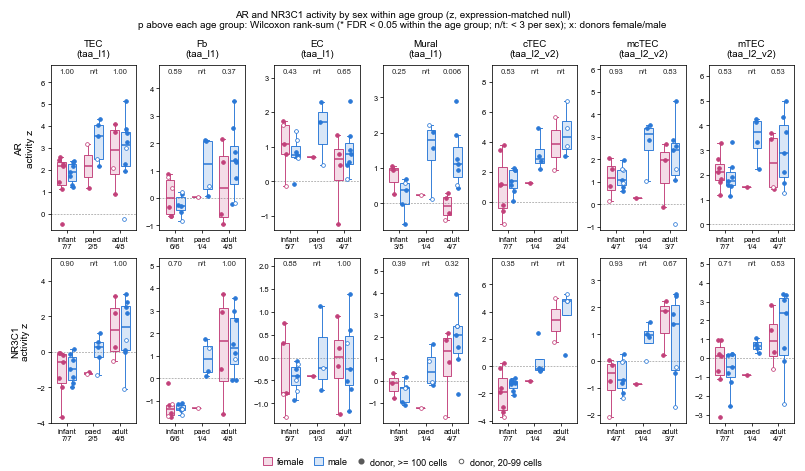

saved thyAgeing_CollecTRI_perDonor_sexDiff_Fig2_PGR_ESR1_ESR2_z.pdf  (183 x 146 mm)


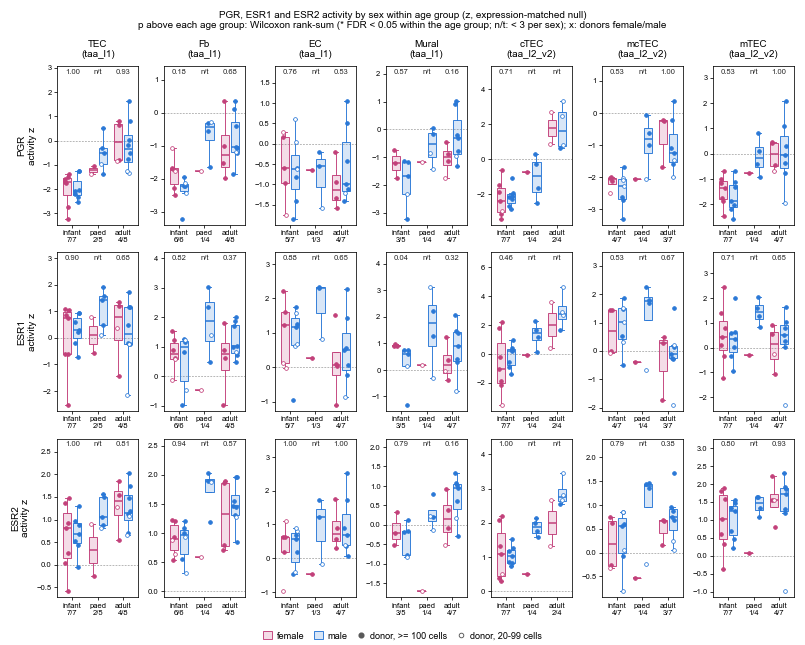

[2026-11-12 17:40:21] main figures done


In [12]:
receptor_grid(T, TESTS, 'z', MAIN_TFS, 'Fig1_AR_NR3C1_z',
              'AR and NR3C1 activity by sex within age group (z, expression-matched null)')
receptor_grid(T, TESTS, 'z', EXTRA_TFS, 'Fig2_PGR_ESR1_ESR2_z',
              'PGR, ESR1 and ESR2 activity by sex within age group (z, expression-matched null)')
log_step('main figures done')


## 6. The alternative: centring each gene before scoring

`z_centred` scores each donor's profile after every gene has been centred on the population's
**average donor** (the gene's mean log1p CP10K over the analysed donors is subtracted). It uses the same
null. A donor's profile then becomes its log fold change against the average donor, so a gene's typical
level never enters the score. That is a second, stronger way of removing what the null removes. This
was the scoring of notebook 05.

Because the reference is common to all donors of a population, centring changes each donor's value but
should barely change how donors **rank** within a population. Below: per-donor `z` against `z_centred`,
the female-vs-male tests repeated on `z_centred`, and how often the two give the same call.


Spearman rho of z vs z_centred across the donors of each population:


population,TEC,Fb,EC,Mural,cTEC,mcTEC,mTEC
source,,,,,,,
AR,0.98,0.98,0.99,0.99,0.98,0.99,0.97
NR3C1,0.99,0.93,0.99,0.99,0.99,1.00,0.99
PGR,0.99,0.98,0.99,0.99,0.98,0.98,0.99
ESR1,0.99,0.99,0.99,1.00,0.99,0.99,0.99
ESR2,0.98,0.98,0.99,1.00,0.98,0.99,0.99


saved thyAgeing_CollecTRI_perDonor_sexDiff_FigS1_zVsCentred.pdf  (183 x 46 mm)


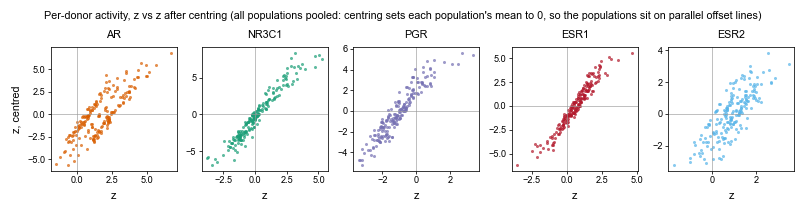

z_centred: female - male median, Wilcoxon rank-sum p (* FDR < 0.05 within the age group)


age_group                  infant       paed            adult
source population                                            
AR     TEC             +0.36  p=1  n/t (2/5)    -0.46  p=0.93
       Fb           +0.74  p=0.59  n/t (1/4)    -1.80  p=0.37
       EC           +0.84  p=0.34  n/t (1/3)    -0.52  p=0.53
       Mural        +1.58  p=0.25  n/t (1/4)  -2.68  p=0.0061
       cTEC         -0.40  p=0.53  n/t (1/4)        n/t (2/4)
       mcTEC        -0.01  p=0.93  n/t (1/4)    -1.22  p=0.83
       mTEC         +0.36  p=0.71  n/t (1/4)    -1.00  p=0.41
NR3C1  TEC           +1.24  p=0.9  n/t (2/5)       -0.49  p=1
       Fb           +0.18  p=0.48  n/t (1/4)       +0.23  p=1
       EC              -0.55  p=1  n/t (1/3)       +0.55  p=1
       Mural        +1.35  p=0.79  n/t (1/4)    -1.76  p=0.41
       cTEC         -1.35  p=0.32  n/t (1/4)        n/t (2/4)
       mcTEC           +0.63  p=1  n/t (1/4)    +0.74  p=0.52
       mTEC          +1.80  p=0.9  n/t (1/4)    -3.74  p=0.93
PGR    TEC             +1.04  p=1  n/t (2/5)    +0.55  p=0.81
       Fb          +1.53  p=0.065  n/t (1/4)    -0.48  p=0.57
       EC           +0.26  p=0.76  n/t (1/3)    -0.34  p=0.53
       Mural        +1.87  p=0.39  n/t (1/4)    -1.53  p=0.16
       cTEC            -0.73  p=1  n/t (1/4)        n/t (2/4)
       mcTEC        +0.52  p=0.53  n/t (1/4)    +2.40  p=0.83
       mTEC         +1.27  p=0.62  n/t (1/4)    -0.12  p=0.93
ESR1   TEC          +0.86  p=0.71  n/t (2/5)    +1.31  p=0.68
       Fb           -0.45  p=0.82  n/t (1/4)    -0.85  p=0.37
       EC           +0.06  p=0.88  n/t (1/3)    -1.02  p=0.53
       Mural       +0.76  p=0.036  n/t (1/4)    -1.80  p=0.32
       cTEC         -2.44  p=0.53  n/t (1/4)        n/t (2/4)
       mcTEC        -0.81  p=0.93  n/t (1/4)    +0.85  p=0.83
       mTEC          +0.02  p=0.8  n/t (1/4)    -0.79  p=0.65
ESR2   TEC           +0.14  p=0.9  n/t (2/5)    +0.47  p=0.93
       Fb           +0.07  p=0.94  n/t (1/4)    -0.26  p=0.93
       EC              +0.05  p=1  n/t (1/3)    +0.19  p=0.93
       Mural        -0.10  p=0.79  n/t (1/4)    -1.83  p=0.16
       cTEC          +0.57  p=0.8  n/t (1/4)        n/t (2/4)
       mcTEC        -0.71  p=0.79  n/t (1/4)    -0.35  p=0.52
       mTEC            -0.58  p=1  n/t (1/4)    -0.30  p=0.93

,tested,p < 0.05,FDR < 0.05
age_group,,,
infant,35,1,0
adult,30,1,0


Female vs male calls, z vs z_centred:


,n
tested comparisons,65
same sign of F - M,61
p < 0.05 with both,2
p < 0.05 with z only,0
p < 0.05 with z_centred only,0
FDR < 0.05 with z,0
FDR < 0.05 with z_centred,0


saved thyAgeing_CollecTRI_perDonor_sexDiff_FigS2_AR_NR3C1_centred.pdf  (183 x 106 mm)


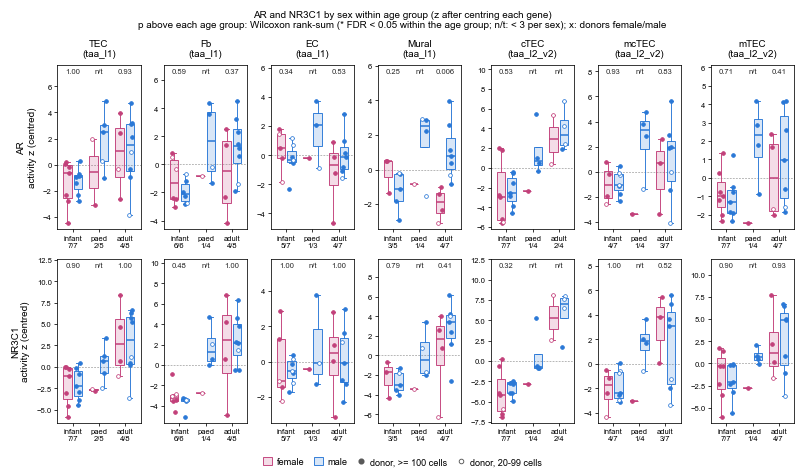

In [13]:
def spearman(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    ok = np.isfinite(a) & np.isfinite(b)
    return float(spearmanr(a[ok], b[ok])[0]) if ok.sum() >= 4 else np.nan


rho = (T.groupby(['source', 'population'], observed=True)
       .apply(lambda g: spearman(g['z'], g['z_centred']), include_groups=False).unstack('population'))
print('Spearman rho of z vs z_centred across the donors of each population:')
display(rho.round(2))

fig = mm_fig(NATURE_W['double'], 46)
axes = fig.subplots(1, len(STEROID_TFS), squeeze=False)[0]
for ax, src in zip(axes, STEROID_TFS):
    g = T[T['source'] == src]
    ax.scatter(g['z'], g['z_centred'], s=4, color=RECEPTOR_STYLE[src][0], lw=0, alpha=0.7, rasterized=True)
    ax.axhline(0, color='0.6', lw=0.4)
    ax.axvline(0, color='0.6', lw=0.4)
    ax.set_title(src, fontsize=7)
    ax.set_xlabel('z')
axes[0].set_ylabel('z, centred')
fig.suptitle('Per-donor activity, z vs z after centring (all populations pooled: centring sets each '
             "population's mean to 0, so the populations sit on parallel offset lines)", fontsize=7)
save_fig(fig, f'{PREFIX}_FigS1_zVsCentred')
plt.show()
plt.close(fig)

TESTS_C = sex_tests(T, 'z_centred')
print('z_centred: female - male median, Wilcoxon rank-sum p (* FDR < 0.05 within the age group)')
show_tests(TESTS_C)

j = TESTS.merge(TESTS_C, on=['population', 'source', 'age_group'], suffixes=('', '_c')).dropna(subset=['p', 'p_c'])
print('Female vs male calls, z vs z_centred:')
display(pd.Series({'tested comparisons': len(j),
                   'same sign of F - M': int((np.sign(j['F_minus_M']) == np.sign(j['F_minus_M_c'])).sum()),
                   'p < 0.05 with both': int(((j['p'] < ALPHA) & (j['p_c'] < ALPHA)).sum()),
                   'p < 0.05 with z only': int(((j['p'] < ALPHA) & (j['p_c'] >= ALPHA)).sum()),
                   'p < 0.05 with z_centred only': int(((j['p'] >= ALPHA) & (j['p_c'] < ALPHA)).sum()),
                   'FDR < 0.05 with z': int((j['padj'] < ALPHA).sum()),
                   'FDR < 0.05 with z_centred': int((j['padj_c'] < ALPHA).sum())}).to_frame('n'))
receptor_grid(T, TESTS_C, 'z_centred', MAIN_TFS, 'FigS2_AR_NR3C1_centred',
              'AR and NR3C1 by sex within age group (z after centring each gene)')


## 7. QC: sequencing depth

No depth correction is applied to the results above; this section asks whether depth could explain
them.

* **Depth by sex.** Do library size or cells per pseudobulk differ between female and male donors
  within an age group? (Wilcoxon rank-sum.) A depth difference between the sexes is what could turn a
  depth effect into a sex effect.
* **Depth in the values.** Spearman correlation of `z` with log10 library size across the donors of a
  population.
* **Depth-residualised z.** Within each population × receptor, `z` is regressed on log10 library size
  and log10 cells (all donors, all ages), and the residual (plus the mean) is tested again by sex. The
  regression runs across age groups, so it can also absorb some of the age difference. That is
  acceptable for a within-age-group comparison, but it is why the residualised values are QC, not the
  result.


Depth by sex within age group (Wilcoxon rank-sum; NaN = fewer than 3 donors of one sex):


,population,age_group,n_F,n_M,median lib_size F,median lib_size M,p lib_size,median n_cells F,median n_cells M,p n_cells
0,TEC,infant,7,7,6358515.0,5278616.0,0.902,1138.0,1278.0,0.902
1,TEC,paed,2,5,19027348.0,7493005.0,NaN,7067.0,994.0,NaN
2,TEC,adult,4,8,12043370.0,16218414.0,0.570,1371.0,1699.0,0.570
3,Fb,infant,6,6,1044432.0,1731584.0,0.818,204.0,524.0,0.589
4,Fb,paed,1,4,45019.0,2256714.0,NaN,31.0,428.0,NaN
5,Fb,adult,4,8,36514891.0,19458044.0,0.683,5970.0,3368.0,0.570
6,EC,infant,5,7,2070829.0,960338.0,0.876,374.0,215.0,0.755
7,EC,paed,1,3,305348.0,660485.0,NaN,146.0,115.0,NaN
8,EC,adult,4,7,17392035.0,5667889.0,1.000,2100.0,2450.0,0.927
9,Mural,infant,3,5,1132650.0,1245312.0,0.786,279.0,453.0,1.000


Spearman rho of z with log10 library size across the donors of each population:


population,TEC,Fb,EC,Mural,cTEC,mcTEC,mTEC
source,,,,,,,
AR,0.21,0.40,0.00,0.09,-0.21,0.49,0.50
NR3C1,0.34,0.60,0.27,0.44,-0.34,0.55,0.38
PGR,0.27,0.33,0.01,0.39,-0.27,0.53,0.37
ESR1,0.27,0.31,-0.04,0.16,-0.27,0.10,0.47
ESR2,0.23,0.38,0.34,0.52,-0.32,0.51,0.29


z_depthres: female - male median, Wilcoxon rank-sum p (* FDR < 0.05 within the age group)


age_group                 infant       paed            adult
source population                                           
AR     TEC          -0.02  p=0.9  n/t (2/5)    -0.49  p=0.68
       Fb          +0.57  p=0.39  n/t (1/4)    -1.27  p=0.15
       EC          +0.19  p=0.43  n/t (1/3)    -0.34  p=0.53
       Mural       +0.68  p=0.39  n/t (1/4)  -1.34  p=0.0061
       cTEC        -0.04  p=0.71  n/t (1/4)        n/t (2/4)
       mcTEC       -0.22  p=0.93  n/t (1/4)    -0.56  p=0.52
       mTEC        +0.22  p=0.53  n/t (1/4)    -0.14  p=0.79
NR3C1  TEC          +0.72  p=0.9  n/t (2/5)       -0.54  p=1
       Fb          +0.28  p=0.59  n/t (1/4)    -0.32  p=0.57
       EC             -0.01  p=1  n/t (1/3)       +0.31  p=1
       Mural          -0.41  p=1  n/t (1/4)    -0.53  p=0.16
       cTEC        -0.48  p=0.46  n/t (1/4)        n/t (2/4)
       mcTEC       -0.52  p=0.53  n/t (1/4)    +0.69  p=0.67
       mTEC        +0.98  p=0.46  n/t (1/4)    -0.84  p=0.65
PGR    TEC            +0.44  p=1  n/t (2/5)    +0.38  p=0.81
       Fb          +0.37  p=0.18  n/t (1/4)    -0.70  p=0.46
       EC             +0.18  p=1  n/t (1/3)    -0.20  p=0.53
       Mural       +0.23  p=0.79  n/t (1/4)   -0.71  p=0.073
       cTEC           -0.44  p=1  n/t (1/4)        n/t (2/4)
       mcTEC       -0.12  p=0.93  n/t (1/4)    +0.32  p=0.67
       mTEC        +0.45  p=0.32  n/t (1/4)    +0.27  p=0.93
ESR1   TEC          -0.27  p=0.9  n/t (2/5)       +0.37  p=1
       Fb          -0.27  p=0.82  n/t (1/4)    -0.40  p=0.28
       EC             -0.04  p=1  n/t (1/3)    -0.93  p=0.65
       Mural       +0.40  p=0.79  n/t (1/4)    -0.66  p=0.23
       cTEC         -0.40  p=0.8  n/t (1/4)        n/t (2/4)
       mcTEC       +0.02  p=0.79  n/t (1/4)       +0.03  p=1
       mTEC        +0.04  p=0.71  n/t (1/4)       +0.03  p=1
ESR2   TEC          +0.08  p=0.9  n/t (2/5)    +0.10  p=0.81
       Fb           +0.03  p=0.7  n/t (1/4)    -0.26  p=0.68
       EC          -0.41  p=0.53  n/t (1/3)    -0.24  p=0.93
       Mural          -0.12  p=1  n/t (1/4)   -0.71  p=0.042
       cTEC        +0.10  p=0.21  n/t (1/4)        n/t (2/4)
       mcTEC       +0.06  p=0.93  n/t (1/4)    -0.47  p=0.38
       mTEC         +0.18  p=0.9  n/t (1/4)       +0.08  p=1

,tested,p < 0.05,FDR < 0.05
age_group,,,
infant,35,0,0
adult,30,2,0


AR and NR3C1: the main test vs the same test on depth-residualised z


,source,population,age_group,n_F,n_M,F_minus_M,p,padj,F_minus_M depth-res.,p depth-res.,padj depth-res.
0,AR,TEC,infant,7,7,0.2767,1.0000,1.0000,-0.0158,0.9015,1.0000
2,AR,TEC,adult,4,8,-0.2255,1.0000,1.0000,-0.4870,0.6828,1.0000
3,AR,Fb,infant,6,6,0.2894,0.5887,1.0000,0.5658,0.3939,1.0000
5,AR,Fb,adult,4,8,-0.9684,0.3677,1.0000,-1.2715,0.1535,0.9818
6,AR,EC,infant,5,7,0.3081,0.4318,1.0000,0.1876,0.4318,1.0000
8,AR,EC,adult,4,7,-0.1561,0.6485,1.0000,-0.3429,0.5273,1.0000
9,AR,Mural,infant,3,5,0.5605,0.2500,1.0000,0.6823,0.3929,1.0000
11,AR,Mural,adult,4,7,-1.1747,0.0061,0.1818,-1.3370,0.0061,0.1818
12,AR,cTEC,infant,7,7,-0.2663,0.5350,1.0000,-0.0429,0.7104,1.0000
15,AR,mcTEC,infant,4,7,0.1094,0.9273,1.0000,-0.2156,0.9273,1.0000


saved thyAgeing_CollecTRI_perDonor_sexDiff_FigS3_AR_NR3C1_depthResidualised.pdf  (183 x 106 mm)


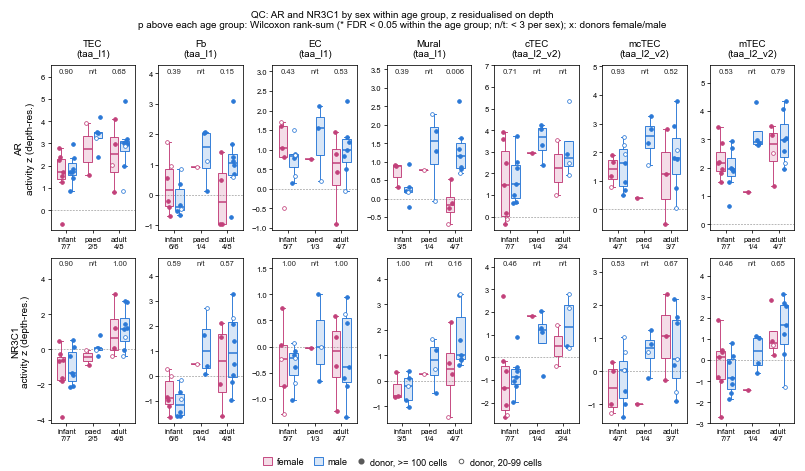

[2026-11-12 17:40:31] QC done


In [14]:
rows = []
A = DON[DON['analysed']]
for (pop, ag), g in A.groupby(['population', 'age_group']):
    f, m = g[g['sex'] == 'F'], g[g['sex'] == 'M']
    row = {'population': pop, 'age_group': ag, 'n_F': len(f), 'n_M': len(m)}
    for col in ('lib_size', 'n_cells'):
        row[f'median {col} F'], row[f'median {col} M'] = f[col].median(), m[col].median()
        row[f'p {col}'] = (mannwhitneyu(f[col], m[col], method='exact').pvalue
                           if min(len(f), len(m)) >= MIN_PER_SEX else np.nan)
    rows.append(row)
DEPTH_SEX = pd.DataFrame(rows)
DEPTH_SEX['population'] = pd.Categorical(DEPTH_SEX['population'], list(POPS), ordered=True)
DEPTH_SEX['age_group'] = pd.Categorical(DEPTH_SEX['age_group'], AGE_GROUPS, ordered=True)
DEPTH_SEX = DEPTH_SEX.sort_values(['population', 'age_group']).reset_index(drop=True)
print('Depth by sex within age group (Wilcoxon rank-sum; NaN = fewer than 3 donors of one sex):')
display(DEPTH_SEX.round({c: 0 for c in DEPTH_SEX.columns if c.startswith('median')} | {'p lib_size': 3, 'p n_cells': 3}))

print('Spearman rho of z with log10 library size across the donors of each population:')
display(T.groupby(['source', 'population'], observed=True)
        .apply(lambda g: spearman(g['z'], g['log10_lib']), include_groups=False).unstack('population').round(2))


def residualise(y, covariates):
    """Residuals of y after least squares on an intercept + covariates, with the mean of y added back."""
    X = np.column_stack([np.ones(len(y))] + [np.asarray(c, float) for c in covariates])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return y - X @ beta + y.mean()


T['z_depthres'] = np.nan
for _, idx in T.groupby(['population', 'source'], observed=True).groups.items():
    g = T.loc[idx]
    T.loc[idx, 'z_depthres'] = residualise(g['z'].to_numpy(float), [g['log10_lib'], g['log10_cells']])

TESTS_D = sex_tests(T, 'z_depthres')
print('z_depthres: female - male median, Wilcoxon rank-sum p (* FDR < 0.05 within the age group)')
show_tests(TESTS_D)
cmp = (TESTS.merge(TESTS_D, on=['population', 'source', 'age_group'], suffixes=('', ' depth-res.'))
       .query('source in @MAIN_TFS').dropna(subset=['p']))
print('AR and NR3C1: the main test vs the same test on depth-residualised z')
display(cmp[['source', 'population', 'age_group', 'n_F', 'n_M', 'F_minus_M', 'p', 'padj',
             'F_minus_M depth-res.', 'p depth-res.', 'padj depth-res.']].round(4))
receptor_grid(T, TESTS_D, 'z_depthres', MAIN_TFS, 'FigS3_AR_NR3C1_depthResidualised',
              'QC: AR and NR3C1 by sex within age group, z residualised on depth')
log_step('QC done')


## 8. Summary (run of 2026-11-12, 1,000 permutations)

**No female-vs-male difference in steroid-receptor activity survives FDR in any age group.**

* **Tests.** 65 receptor × population × age-group comparisons could be tested (35 in infants, 30 in
  adults). The paediatric group (1–2 female donors per population) and adult cTEC (2 females) are drawn
  but not tested. *p* < 0.05 in 2 of 65 (chance alone gives about 3); FDR < 0.05 in none.
* **AR.** The lowest *p* is AR in adult **Mural** cells: female − male −1.17 z (4 F vs 7 M), *p* = 0.006,
  FDR 0.18 over the 30 adult tests. The direction is shared: in adults, AR's female − male difference is
  negative in all 6 testable populations, and in infants it is positive in 6 of 7. Only Mural reaches
  *p* < 0.05, and the populations share donors (the `taa_l1` TEC pool contains the three `taa_l2_v2` TEC
  populations), so this is a weak, consistent male bias in adults, not an established effect.
* **NR3C1.** No difference anywhere (lowest *p* 0.32, adult Mural).
* **Extras.** ESR1 in infant Mural *p* = 0.036 (FDR 1); nothing else below 0.05 for PGR, ESR1 or ESR2.
* **Activity levels** (median z over all donors): AR targets sit above expression-matched genes in
  epithelium (TEC 2.3, cTEC 2.2, mTEC 2.2, mcTEC 1.6) and less so in stroma (EC 0.8, Mural 0.6,
  Fb 0.2). NR3C1 is near 0 overall and rises with age (notebook 07); PGR is below 0 everywhere.
* **Centring (section 6) changes nothing material.** Per-donor `z` and `z_centred` agree at Spearman
  0.93–1.00 within each population. The female − male sign agrees in 61 of 65 comparisons, and the
  same 2 comparisons have *p* < 0.05. `z_centred` reproduces notebook 05's `z` exactly (same donors,
  universe, null and seed; checked when this notebook was built).
* **Depth (section 7).** Library size and cells per pseudobulk do not differ between the sexes in any
  testable group (all *p* ≥ 0.41), so depth cannot create a sex difference here. `z` does follow
  library size in some populations (Spearman up to 0.60, NR3C1 in Fb). After depth residualisation, AR
  in adult Mural is unchanged (*p* = 0.006); ESR2 in adult Mural reaches *p* = 0.042 and infant ESR1 in
  Mural drops out; still no FDR hit.


## 9. Outputs

`results/` (prefix `thyAgeing_CollecTRI_perDonor_sexDiff_`):

* `scores_perDonor_steroidReceptors.csv` — **the Supplementary Table**: every analysed donor ×
  population × receptor with its metadata, `score`, `null_mean`, `null_sd`, `z`, the centred
  equivalents (`*_centred`) and `z_depthres`;
* `sexTests.csv` — female vs male per value (`z`, `z_centred`, `z_depthres`) × receptor × population ×
  age group: donors, medians, F − M, *p*, `padj`;
* `donors.csv` — every pseudobulk of the seven populations with its filter flags; `depthBySex.csv` —
  section 7;
* `scores_perDonor.csv` — the score cache.

`figures/`: `Fig1_AR_NR3C1_z`, `Fig2_PGR_ESR1_ESR2_z`, `FigS1_zVsCentred`, `FigS2_AR_NR3C1_centred`,
`FigS3_AR_NR3C1_depthResidualised` (PDF, sized in mm).


In [15]:
SUPP = T[META + ['source', 'n_genes', 'n_targets', 'score', 'null_mean', 'null_sd', 'z', 'score_centred',
                 'null_mean_centred', 'null_sd_centred', 'z_centred', 'z_depthres']]
SUPP.to_csv(f'{RESULTS}/{PREFIX}_scores_perDonor_steroidReceptors.csv', index=False)
pd.concat([TESTS, TESTS_C, TESTS_D], ignore_index=True).to_csv(f'{RESULTS}/{PREFIX}_sexTests.csv', index=False)
DON.drop(columns=['row']).to_csv(f'{RESULTS}/{PREFIX}_donors.csv', index=False)
DEPTH_SEX.to_csv(f'{RESULTS}/{PREFIX}_depthBySex.csv', index=False)
for folder in (RESULTS, FIGURES):
    print(folder)
    for f in sorted(x for x in os.listdir(folder) if x.startswith(PREFIX)):
        print('   ', f)
log_step('=== notebook done')


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/notebooks/hormone2cell/_builders/../final_versions/github/results
    thyAgeing_CollecTRI_perDonor_sexDiff_depthBySex.csv
    thyAgeing_CollecTRI_perDonor_sexDiff_donors.csv
    thyAgeing_CollecTRI_perDonor_sexDiff_progress.log
    thyAgeing_CollecTRI_perDonor_sexDiff_scores_perDonor.csv
    thyAgeing_CollecTRI_perDonor_sexDiff_scores_perDonor_steroidReceptors.csv
    thyAgeing_CollecTRI_perDonor_sexDiff_sexTests.csv
/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/notebooks/hormone2cell/_builders/../final_versions/github/figures
    thyAgeing_CollecTRI_perDonor_sexDiff_Fig1_AR_NR3C1_z.pdf
    thyAgeing_CollecTRI_perDonor_sexDiff_Fig2_PGR_ESR1_ESR2_z.pdf
    thyAgeing_CollecTRI_perDonor_sexDiff_FigS1_zVsCentred.pdf
    thyAgeing_CollecTRI_perDonor_sexDiff_FigS2_AR_NR3C1_centred.pdf
    thyAgeing_CollecTRI_perDonor_sexDiff_FigS3_AR_NR3C1_depthResidualised.pdf
[2026-11-12 17:40:31] === notebook done
